# Predicting Sephora Skincare Ratings: Does Skin Type Help?
**CSE 158/258 — Assignment 2**

**Question:** Given a reviewer and a skincare product, can we predict the star rating they will give?
Additionally, does knowing the reviewer's self-reported traits (skin type, skin tone, eye color, hair color)
make the predictions more accurate?

## 1. Predictive task
- **Input:** who the reviewer is and which product they're rating, plus extra details:
  - About the reviewer: skin type, skin tone, eye color, hair color
  - About the product: category (e.g. moisturizer, cleanser), brand, price
- **Output:** the star rating, from 1 to 5.
- **How we measure accuracy:** Mean Squared Error (MSE) of the test set:

  $$\text{MSE} = \frac{1}{N}\sum_{n=1}^{N}\left(\text{actual rating}_n - \text{predicted rating}_n\right)^2$$
- **What we compare against:**
  1. **Variance baseline:** always guess the average rating, no matter who the reviewer is or what
   the product is. The MSE of this guess equals the variance of the ratings, the natural spread
   of the data. Any model that can't beat it has learned nothing useful about reviewers or products.
  2. **Bias model:** starts from the average rating, then adjusts for two things:
     - **the reviewer:** some people rate everything high, others are harsher
     - **the product:** some products are rated well by almost everyone 
    
      If adding skin type and tone doesn't beat this model,
     those traits aren't telling us anything new beyond each reviewer's general generosity and each
     product's overall reputation.
- **Keeping the test fair:**
  - We split the reviews into 80% for training, 10% for tuning, and 10% for the final test.
    The final test set is only used once.
  - We don't use any product stats (like average rating) that were calculated from all reviews,
    since those would include the test answers.
  - We check accuracy separately for new vs. experienced reviewers and for each skin tone,
    so a good overall score can't hide a group the model does badly on.

In [18]:
import glob, os, random
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import sparse
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

SEED = 0
np.random.seed(SEED); random.seed(SEED)
plt.rcParams["figure.figsize"] = (7, 4)

DATA_DIR = "data"   # folder with product_info.csv and reviews_*.csv from Kaggle

## 2. Data

### Context: where the data comes from

The dataset is [**Sephora Products and Skincare Reviews**](https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews/data), published on Kaggle
It was built with two [Python web scrapers](https://github.com/nadyinky/sephora-analysis/tree/main/sephora_scraper):

1. **Product scraper:** collected information on every product sold on sephora.com
   (name, brand, category, price, number of "loves", average rating, ingredients, etc.)
   through Sephora's own website API
2. **Reviews scraper:** collected every customer review for the **skincare** products.

The author collected the data for a portfolio
project on exploratory analysis and sentiment analysis of reviews.

**What each review contains:**
- the star rating (1–5) and whether the reviewer recommends the product
- the review title and text, and how many people found it helpful
- the reviewer's ID and **self-reported traits**: skin type, skin tone, eye color, hair color.
  Sephora asks reviewers for these when they write a review, but they're optional,
  so some are missing.

### Discussion: how we processed the data

The scraper already cleaned the raw data but on top of that, we:

1. **Combined the review files** into one table.
2. **Removed unusable rows:** reviews missing a reviewer ID, product ID or rating.
3. **Removed duplicates:** if a reviewer rated the same product more than once,
   we kept only their most recent review.
4. **Added product category** (e.g. moisturizer, cleanser) from `product_info.csv`, matched by product ID.
5. **Filled missing traits with `"unknown"`** instead of dropping those reviews.
   Whether someone chooses to share their skin type may itself be informative.
6. **Grouped prices into 5 equal-sized buckets** (cheapest 20% through most expensive 20%).
7. **Left out product-level stats** (`rating`, `reviews`, `loves_count` from `product_info.csv`).
   These were calculated from *all* reviews, including the ones we test on, so using them
   would let the model peek at the answers.
8. **Left out the review text** for rating prediction, since it's written at the same time
   as the rating and wouldn't be available before someone reviews a product.

In [19]:
# ---------- Load ----------
review_files = sorted(glob.glob(os.path.join(DATA_DIR, "reviews_*.csv")))
products = pd.read_csv(os.path.join(DATA_DIR, "product_info.csv"), dtype={"product_id": str})

# Step 1: combine the review files into one table
reviews = pd.concat(
    [pd.read_csv(f, dtype={"author_id": str, "product_id": str}, low_memory=False) for f in review_files],
    ignore_index=True,
)
reviews = reviews.loc[:, ~reviews.columns.str.startswith("Unnamed")]   # drop leftover index column

# Step 2: remove rows missing a reviewer ID, product ID or rating
before = len(reviews)
reviews = reviews.dropna(subset=["author_id", "product_id", "rating"])

# Step 3: keep only each reviewer's most recent review of a product
before = len(reviews)
reviews["submission_time"] = pd.to_datetime(reviews["submission_time"], errors="coerce")
reviews = (reviews.sort_values("submission_time")
                  .drop_duplicates(["author_id", "product_id"], keep="last")
                  .reset_index(drop=True))

# Step 4: add product category from product_info.csv
# Step 7: only category columns are merged; product-level stats (rating, reviews, loves_count)
#         are deliberately NOT merged, since they were computed from all reviews, including the test set
df = reviews.merge(products[["product_id", "secondary_category"]], on="product_id", how="left")

# Step 5: fill missing traits/attributes with "unknown" instead of dropping the review
USER_ATTRS = ["skin_type", "skin_tone", "eye_color", "hair_color"]
ITEM_ATTRS = ["secondary_category", "brand_name"]
for c in USER_ATTRS + ITEM_ATTRS:
    df[c] = df[c].fillna("unknown").astype(str)

# Step 6: group prices into 5 equal-sized buckets (cheapest 20% ... most expensive 20%)
df["price_bucket"] = (pd.qcut(df["price_usd"], 5, labels=False, duplicates="drop")
                        .fillna(-1).astype(int).astype(str))

# Step 8: drop review text/title, since they're written together with the rating and would leak it
df = df.drop(columns=["review_text", "review_title"])

df.head(5)

,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd,secondary_category,price_bucket
0,1386893505,4,NaN,1.000000,7,0,7,2008-08-28,light,unknown,combination,unknown,P7880,Soy Hydrating Gentle Face Cleanser,fresh,39.0,Cleansers,2
1,927434292,5,NaN,0.933333,15,1,14,2008-08-28,light,unknown,combination,unknown,P449599,Mini Anti-Aging Cleansing Gel,Peter Thomas Roth,12.0,Mini Size,0
2,927434292,5,NaN,0.933333,15,1,14,2008-08-28,light,unknown,combination,unknown,P39274,Anti-Aging Cleansing Gel,Peter Thomas Roth,39.0,Cleansers,2
3,1309726069,5,NaN,0.666667,6,2,4,2008-08-29,light,unknown,unknown,unknown,P122774,All About Eyes Eye Cream,CLINIQUE,37.0,Eye Care,2
4,924698392,3,NaN,0.000000,1,1,0,2008-08-29,lightMedium,unknown,combination,unknown,P34402,Acne Control Clarifying Body Spray,Murad,48.0,Treatments,2


### Exploratory analysis

#### 1. Rating distribution
Ratings are heavily skewed toward 5 stars. A model that always guesses the average will already be
close most of the time, so the real test is predicting the **low** ratings.

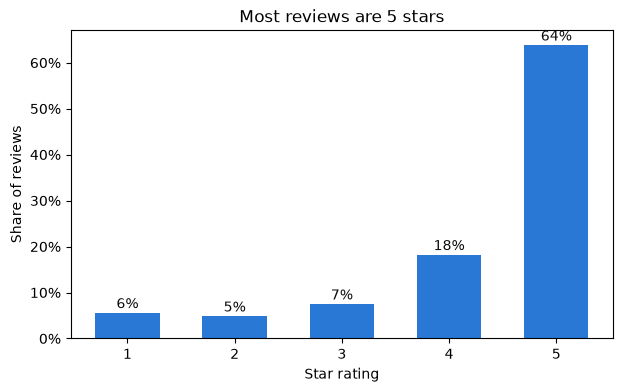

mean rating 4.30 | var 1.32


In [20]:
overall_mean=df.rating.mean()
counts = df["rating"].value_counts().sort_index()
share = counts / counts.sum()
fig, ax = plt.subplots()
ax.bar(counts.index, share, color="#2a78d6", width=0.6)
for x, s in zip(counts.index, share):
    ax.text(x, s + 0.01, f"{s:.0%}", ha="center", color="#0b0b0b", fontsize=10)
ax.set(title="Most reviews are 5 stars", xlabel="Star rating", ylabel="Share of reviews")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
plt.show()
print(f"mean rating {overall_mean:.2f} | var {df.rating.var():.2f}")

#### 2. Reviews per user and per product
Most users wrote **one** review, so there's almost no
history to learn an individual's taste from. Products, by contrast, have plenty of reviews. We
expect product effects to be easy to learn and user effects to be hard.

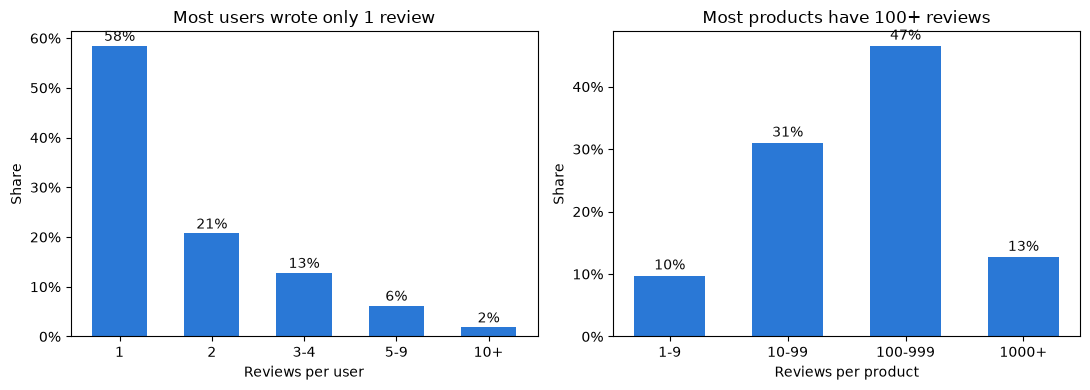

users with 1 review: 58% | median reviews per user: 1
median reviews per product: 164 | max: 15,853


In [21]:
per_user = df.groupby("author_id").size()
per_item = df.groupby("product_id").size()
u_bins, u_labels = [1, 2, 3, 5, 10, np.inf], ["1", "2", "3-4", "5-9", "10+"]
i_bins, i_labels = [1, 10, 100, 1000, np.inf], ["1-9", "10-99", "100-999", "1000+"]
u_share = pd.cut(per_user, u_bins, right=False, labels=u_labels).value_counts(normalize=True).sort_index()
i_share = pd.cut(per_item, i_bins, right=False, labels=i_labels).value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s, title, xl in [(axes[0], u_share, "Most users wrote only 1 review", "Reviews per user"),
                         (axes[1], i_share, "Most products have 100+ reviews", "Reviews per product")]:
    ax.bar(s.index.astype(str), s.values, color="#2a78d6", width=0.6)
    for x, v in enumerate(s.values):
        ax.text(x, v + 0.01, f"{v:.0%}", ha="center", color="#0b0b0b", fontsize=10)
    ax.set(title=title, xlabel=xl, ylabel="Share")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"users with 1 review: {np.mean(per_user == 1):.0%} | median reviews per user: {per_user.median():.0f}")
print(f"median reviews per product: {per_item.median():.0f} | max: {per_item.max():,}")

#### 3. Do skin traits relate to ratings?
Most reviewers do share their traits: 90% report skin type, 84% skin tone, 81% eye color,
and 80% hair color. So missing data isn't what limits these features. If skin traits end up
adding little to the model, it will be because they don't relate to ratings, not because
reviewers left them out.

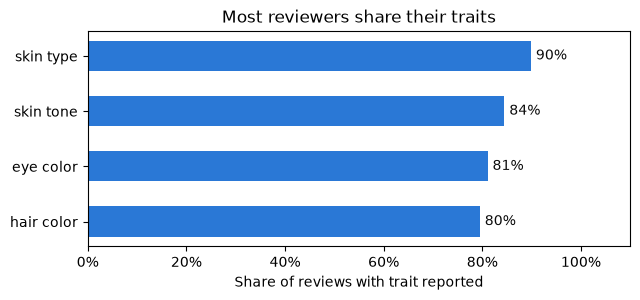

In [22]:
reported = (df[USER_ATTRS] != "unknown").mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh([c.replace("_", " ") for c in reported.index], reported.values, color="#2a78d6", height=0.55)
for y, v in enumerate(reported.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color="#0b0b0b", fontsize=10)
ax.set(title="Most reviewers share their traits", xlabel="Share of reviews with trait reported", xlim=(0, 1.1))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
plt.show()

Ratings barely change across skin types or skin tones. 

- **Skin type:** oily skin gives the lowest average (4.27) and combination skin the highest (4.31),
  a gap of only **0.04 stars**.
- **Skin tone:** the gap is larger, **0.11 stars** (porcelain 4.23 to medium 4.33), but the
  extreme groups are small (porcelain has under 1,600 reviews), so part of that spread may be noise.
- **"Unknown" isn't different:** reviewers who didn't share their traits rate about the same as
  everyone else, so choosing not to report them isn't a signal either.

For comparison, individual ratings vary with a standard deviation of 1.15 stars, so these group
differences are tiny next to the normal spread between reviews.

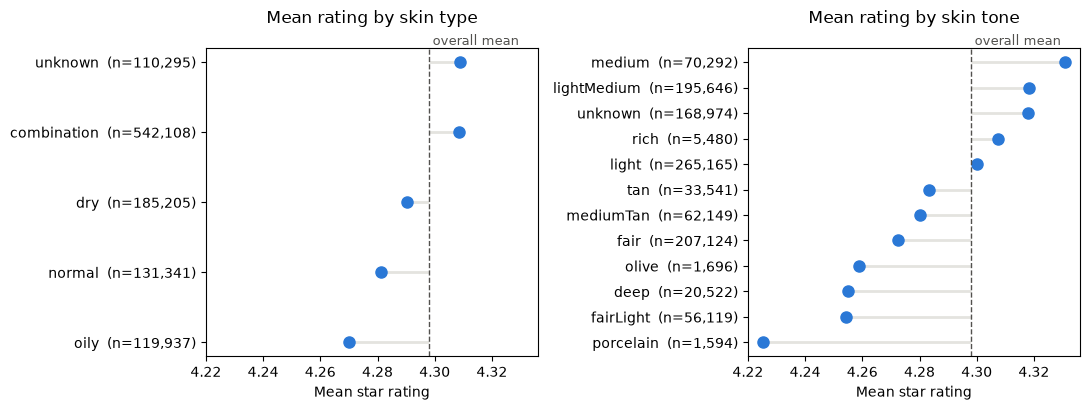

skin_type: range of group means = 0.04 stars
skin_tone: range of group means = 0.11 stars


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, col in zip(axes, ["skin_type", "skin_tone"]):
    g = df.groupby(col)["rating"].agg(["mean", "size"])
    g = g[g["size"] >= 1000].sort_values("mean")
    ax.hlines(range(len(g)), overall_mean, g["mean"], color="#e4e3df", linewidth=2)
    ax.plot(g["mean"], range(len(g)), "o", color="#2a78d6", markersize=8)
    ax.axvline(overall_mean, color="#52514e", linestyle="--", linewidth=1)
    ax.set_yticks(range(len(g)), [f"{i}  (n={n:,})" for i, n in zip(g.index, g["size"])])
    ax.set_title(f"Mean rating by {col.replace('_', ' ')}", pad=18)
    ax.set_xlabel("Mean star rating")
    ax.grid(axis="y", visible=False)
for ax in axes:
    ax.text(overall_mean, ax.get_ylim()[1], " overall mean", color="#52514e", fontsize=9, va="bottom")
plt.tight_layout(); plt.show()
for col in ["skin_type", "skin_tone"]:
    g = df.groupby(col)["rating"].agg(["mean", "size"]); g = g[g["size"] >= 1000]
    print(f"{col}: range of group means = {g['mean'].max() - g['mean'].min():.2f} stars")

Skin type might matter *for specific products* even if it doesn't matter overall (e.g., oily skin
rating moisturizers lower). Each cell shows how far a skin type's average rating is from that
category's average.

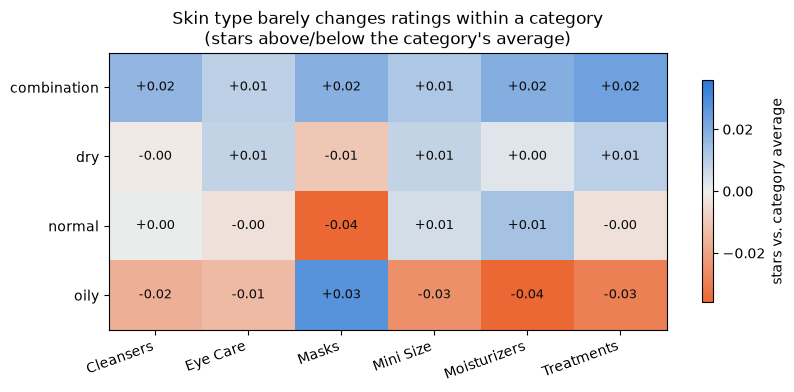

largest skin-type effect within a category: 0.04 stars


In [24]:
top_cats = df["secondary_category"].value_counts().index[:6]
sub = df[df.secondary_category.isin(top_cats) & (df.skin_type != "unknown")]
pivot = sub.pivot_table(index="skin_type", columns="secondary_category", values="rating", aggfunc="mean")
diff = pivot - pivot.mean(axis=0)                     # each cell vs. that category's average
lim = np.abs(diff.values).max()
cmap = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(diff.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(diff.columns)), diff.columns, rotation=20, ha="right")
ax.set_yticks(range(len(diff.index)), diff.index)
for (r, c), v in np.ndenumerate(diff.values):
    ax.text(c, r, f"{v:+.2f}", ha="center", va="center", color="#0b0b0b", fontsize=9)
ax.grid(False)
ax.set_title("Skin type barely changes ratings within a category\n(stars above/below the category's average)")
fig.colorbar(im, ax=ax, shrink=0.8, label="stars vs. category average")
plt.show()
print(f"largest skin-type effect within a category: {lim:.2f} stars")

**Do skin traits relate to ratings?** Only very weakly. Reviewers report their traits most of the time,
but the average rating varies by at most about 0.1 stars across skin tones and 0.04 stars across skin
types, even within product categories. We therefore expect skin features to improve the model only
slightly, if at all.

#### 4. Do price and time matter?
Mid-priced and expensive products rate slightly higher than the cheapest ones, but the gap is small.

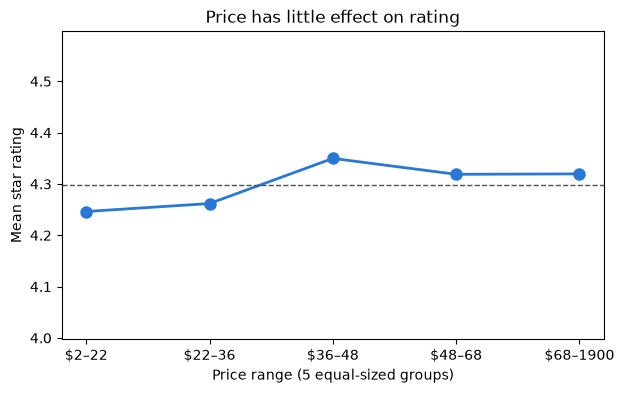

In [25]:
pb = df[df.price_bucket != "-1"].groupby("price_bucket")["rating"].agg(["mean", "size"])
edges = pd.qcut(df["price_usd"], 5, duplicates="drop").cat.categories
labels = [f"${int(e.left)}–{int(e.right)}" for e in edges]
fig, ax = plt.subplots()
ax.plot(labels, pb["mean"].values, "o-", color="#2a78d6", linewidth=2, markersize=8)
ax.axhline(overall_mean, color="#52514e", linestyle="--", linewidth=1)
ax.set(title="Price has little effect on rating", xlabel="Price range (5 equal-sized groups)",
       ylabel="Mean star rating", ylim=(overall_mean - 0.3, overall_mean + 0.3))
plt.show()

Review volume grew sharply after 2017 and peaked around 2020. Average ratings drifted down from
about 4.45 to 4.3 over the same period. Since we split the data randomly, not by time, this drift
affects all splits equally.

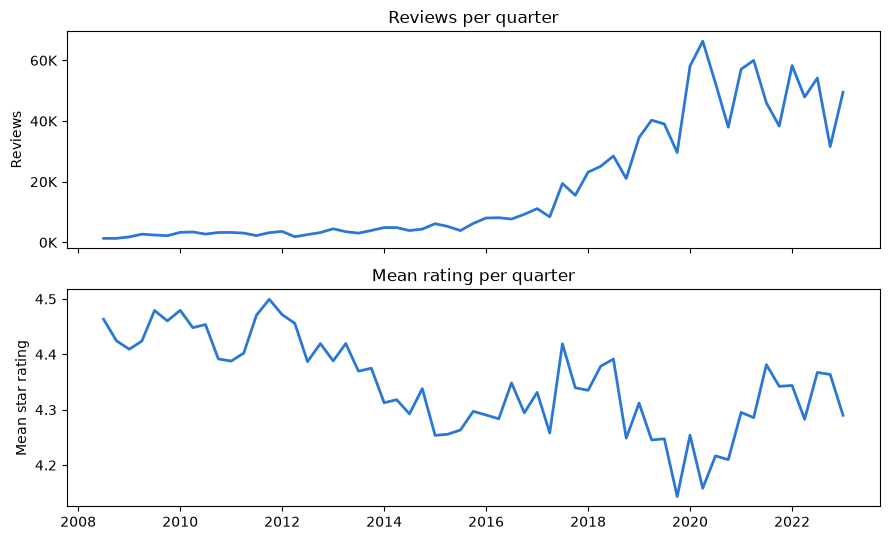

busiest quarter starts 2020-04; last quarter (2023) is partial, data ends March 21


In [26]:
q = df.set_index("submission_time")["rating"].resample("QS").agg(["mean", "size"])
q = q[q["size"] >= 500]
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(q.index, q["size"], color="#2a78d6", linewidth=2)
axes[0].set(title="Reviews per quarter", ylabel="Reviews")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
axes[1].plot(q.index, q["mean"], color="#2a78d6", linewidth=2)
axes[1].set(title="Mean rating per quarter", ylabel="Mean star rating")
plt.tight_layout(); plt.show()
print(f"busiest quarter starts {q['size'].idxmax():%Y-%m}; last quarter (2023) is partial, data ends March 21")

## 3. Modeling

### Context: framing the task as an ML problem

- **Input:** a (reviewer, product) pair, plus side information:
  - reviewer traits: skin type, skin tone, eye color, hair color (or "unknown")
  - product attributes: category, brand, price range
- **Output:** a predicted star rating $\hat{r}(u, i)$, treated as a continuous number
  (so a prediction like 4.6 is allowed).
- **What is optimized:** squared error on the training reviews, plus an L2 penalty that keeps
  parameters small to avoid overfitting:

  $$\min \sum_{(u,i) \in \text{train}} \left(r_{u,i} - \hat{r}(u,i)\right)^2 + \lambda \cdot \text{(size of parameters)}$$

  This matches our evaluation metric (MSE), so the models are trained on exactly what they're tested on.

**Which models fit this task?** The EDA points to two facts that shape the choice:
1. **Users are sparse** (58% wrote one review), so models that learn each user's personal taste
   will have little to work with.
2. **Products are well-reviewed** (median 164 reviews), so product-level effects should be easy to learn.

We compare four models of increasing complexity:

| Model | Prediction |
|---|---|
| Variance baseline | $\hat{r} = \alpha$ (the average rating) |
| Bias model | $\hat{r} = \alpha + \beta_u + \beta_i$ |
| Latent factor model | $\hat{r} = \alpha + \beta_u + \beta_i + \gamma_u \cdot \gamma_i$ |
| Hybrid (bias + features) | $\hat{r} = \alpha + \beta_u + \beta_i + w \cdot x_{u,i}$ |

- $\beta_u$: how generous reviewer $u$ is compared to average
- $\beta_i$: how well-liked product $i$ is compared to average
- $\gamma_u, \gamma_i$: vectors describing a reviewer's taste and a product's traits; their dot product
  is high when they match
- $x_{u,i}$: one-hot encoded reviewer traits and product attributes; $w$: learned weights


### Discussion: advantages and disadvantages

| Model | Advantages | Disadvantages |
|---|---|---|
| **Variance baseline** | No training; impossible to overfit | Ignores everything about the reviewer and product |
| **Bias model** | Fast closed-form updates; few parameters; captures "generous reviewer" and "great product" | Can't model *interactions*, e.g. that a person who loves one serum will love a similar one |
| **Latent factor** | Learns personal taste × product traits; the standard collaborative-filtering model | Needs several reviews per user to learn $\gamma_u$ (most of our users have one); slow to train with SGD; more hyperparameters ($K$, $\lambda$, learning rate) |
| **Hybrid** | Uses information even for brand-new reviewers (their skin traits); weights are interpretable | Traits are self-reported and sometimes missing; the EDA shows they relate only weakly to ratings |

**Complexity and efficiency:**
- **Bias model:** one parameter per user and per product (~500K), fit in seconds per pass.
- **Latent factor model:** adds $K$ parameters per user and product. Our SGD loop is plain Python,
  so training takes several minutes on 870K reviews.
- **Hybrid:** adds only a few hundred weights, fit with sparse ridge regression in seconds.

**Implementation challenges:**
- **New users and products:** reviewers or products in the test set that never appear in training
  have no learned $\beta$ or $\gamma$. We set their terms to 0, so predictions fall back to
  the simpler parts of the model.
- **Scale:** with ~1M reviews, everything must be vectorized or stored in sparse matrices.
- **Tuning:** each model has a regularization strength (and the latent factor model also has $K$).
  All are chosen on the validation set, never the test set.

### Code walkthrough

**Train / validation / test split.** We shuffle all reviews and split 80/10/10. The validation set
is used to choose hyperparameters; the test set is used to test the model on unseen data

In [27]:
SEED = 0
np.random.seed(SEED)

idx = np.random.permutation(len(df))
n_tr, n_va = int(0.8 * len(df)), int(0.9 * len(df))
train, valid, test = df.iloc[idx[:n_tr]], df.iloc[idx[n_tr:n_va]], df.iloc[idx[n_va:]]
print(f"train {len(train):,} | valid {len(valid):,} | test {len(test):,}")

def mse(y, yhat):
    return float(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2))

# Model 1: variance baseline -- always predict the training-set average
alpha_global = train.rating.mean()
results = {"Variance baseline": {s: mse(d.rating, np.full(len(d), alpha_global))
                                 for s, d in [("valid", valid), ("test", test)]}}
print(f"average rating {alpha_global:.3f} | valid MSE {results['Variance baseline']['valid']:.4f}")

train 871,108 | valid 108,889 | test 108,889
average rating 4.298 | valid MSE 1.3180


**Model 2: bias model.** Instead of gradient descent, we use the closed-form alternating updates
from lecture. Holding the other parameters fixed, each one has an exact solution:

$$\alpha = \text{mean}(r - \beta_u - \beta_i), \quad
\beta_u = \frac{\sum_{i \in I_u} (r_{u,i} - \alpha - \beta_i)}{\lambda + |I_u|}, \quad
\beta_i = \frac{\sum_{u \in U_i} (r_{u,i} - \alpha - \beta_u)}{\lambda + |U_i|}$$

The $\lambda$ in the denominator shrinks the bias of reviewers with few reviews toward 0. That matters
here: a reviewer with one 1-star review shouldn't be labeled "always harsh" on that evidence alone.
We cycle through the updates 15 times and pick $\lambda$ on the validation set.

In [28]:
from collections import defaultdict

def to_lists(d):
    return list(zip(d.author_id.values, d.product_id.values, d.rating.values.astype(float)))

tr = to_lists(train)
items_per_user, users_per_item = defaultdict(list), defaultdict(list)   # who reviewed what
for u, i, r in tr:
    items_per_user[u].append((i, r))
    users_per_item[i].append((u, r))

def fit_bias(lam, iters=15):
    alpha, bu, bi = alpha_global, defaultdict(float), defaultdict(float)
    for _ in range(iters):
        alpha = np.mean([r - bu[u] - bi[i] for u, i, r in tr])
        for u, lst in items_per_user.items():
            bu[u] = sum(r - alpha - bi[i] for i, r in lst) / (lam + len(lst))
        for i, lst in users_per_item.items():
            bi[i] = sum(r - alpha - bu[u] for u, r in lst) / (lam + len(lst))
    return alpha, bu, bi

def predict_bias(model, d):
    alpha, bu, bi = model
    # .get(..., 0.0): unseen reviewers/products get a bias of 0
    return np.array([alpha + bu.get(u, 0.0) + bi.get(i, 0.0) for u, i in zip(d.author_id, d.product_id)])

bias_scores = {}
for lam in [0.25, 0.5, 1, 2, 5]:
    bias_scores[lam] = mse(valid.rating, predict_bias(fit_bias(lam), valid))
    print(f"lambda={lam:>4}: valid MSE {bias_scores[lam]:.4f}")
best_lam = min(bias_scores, key=bias_scores.get)
bias_model = fit_bias(best_lam)
results["Bias model"] = {"valid": bias_scores[best_lam], "test": mse(test.rating, predict_bias(bias_model, test))}
print(f"best lambda = {best_lam}")

lambda=0.25: valid MSE 1.1328
lambda= 0.5: valid MSE 1.1052
lambda=   1: valid MSE 1.0869
lambda=   2: valid MSE 1.0887
lambda=   5: valid MSE 1.1197
best lambda = 1


**Model 3: latent factor model.** Adds a $K$-dimensional taste vector $\gamma_u$ for each reviewer
and a trait vector $\gamma_i$ for each product. There's no closed form here, so we use stochastic
gradient descent (SGD): for each training review, compute the error and nudge every parameter
to reduce it.

Implementation choices:
- **Start from the fitted bias model:** $\alpha, \beta_u, \beta_i$ are initialized from Model 2, so SGD
  only has to learn the interaction term. This converges faster and is more stable.
- **Small random $\gamma$ values (std 0.1):** if all started at 0, every gradient would be 0 and nothing
  would be learned.
- **Integer indices and NumPy arrays** instead of dictionaries, for speed.
- **Unseen reviewers or products:** the $\gamma_u \cdot \gamma_i$ term is skipped and the prediction
  falls back to the bias terms.
- **Small hyperparameter grid:** each setting takes minutes to train, so we try four.

In [ ]:
u_index = {u: k for k, u in enumerate(train.author_id.unique())}
i_index = {i: k for k, i in enumerate(train.product_id.unique())}
tr_u = train.author_id.map(u_index).values
tr_i = train.product_id.map(i_index).values
tr_r = train.rating.values.astype(float)

def fit_lfm(K, lam, lr=0.01, epochs=15):
    rng = np.random.default_rng(SEED)
    alpha, bu0, bi0 = bias_model                               # pick up  from Model 2
    bu = np.array([bu0[u] for u in u_index]); bi = np.array([bi0[i] for i in i_index])
    gu = rng.normal(0, 0.1, (len(u_index), K)); gi = rng.normal(0, 0.1, (len(i_index), K))
    order = np.arange(len(tr_r))
    for _ in range(epochs):
        rng.shuffle(order)                                     # new review order each pass
        for n in order:
            u, i = tr_u[n], tr_i[n]
            err = tr_r[n] - (alpha + bu[u] + bi[i] + gu[u] @ gi[i])
            bu[u] += lr * (err - lam * bu[u])
            bi[i] += lr * (err - lam * bi[i])
            gu_old = gu[u].copy()                              # update both vectors from the same old values
            gu[u] += lr * (err * gi[i] - lam * gu[u])
            gi[i] += lr * (err * gu_old - lam * gi[i])
    return alpha, bu, bi, gu, gi

def predict_lfm(model, d):
    alpha, bu, bi, gu, gi = model
    u = d.author_id.map(u_index); i = d.product_id.map(i_index)
    has_u, has_i = u.notna().values, i.notna().values
    u, i = u.fillna(0).astype(int).values, i.fillna(0).astype(int).values
    pred = alpha + np.where(has_u, bu[u], 0) + np.where(has_i, bi[i], 0)
    pred += np.where(has_u & has_i, np.sum(gu[u] * gi[i], axis=1), 0)   # interaction only if both seen
    return pred

lfm_scores = {}
for K, lam in [(2, 0.1), (5, 0.1), (5, 0.05), (10, 0.1)]:
    m = fit_lfm(K, lam)
    lfm_scores[(K, lam)] = (mse(valid.rating, predict_lfm(m, valid)), m)
    print(f"K={K:>2}, lambda={lam}: valid MSE {lfm_scores[(K, lam)][0]:.4f}")
best_cfg = min(lfm_scores, key=lambda k: lfm_scores[k][0])
lfm_model = lfm_scores[best_cfg][1]
results["Latent factor"] = {"valid": lfm_scores[best_cfg][0], "test": mse(test.rating, predict_lfm(lfm_model, test))}
print(f"best (K, lambda) = {best_cfg}")

K= 2, lambda=0.1: valid MSE 1.0955
K= 5, lambda=0.1: valid MSE 1.0951
K= 5, lambda=0.05: valid MSE 1.0958
K=10, lambda=0.1: valid MSE 1.0956
best (K, lambda) = (5, 0.1)


**Model 4: hybrid (bias model + features).** Tests our main question: do reviewer traits add
information beyond the bias terms? We fit a ridge regression on what the bias model gets *wrong*
(its residuals, $r - \hat{r}_{\text{bias}}$), then add its correction to the bias prediction.

Features (all one-hot encoded):
- reviewer traits: skin type, skin tone, eye color, hair color (with "unknown" as its own value)
- product attributes: category, brand, price range
- **interactions:** skin type × category and skin tone × category. The EDA suggested any effect
  would be product-specific (e.g. oily skin rating moisturizers lower), so the model needs
  these combinations to capture it.

Implementation choices:
- **Fitting on residuals** lets features explain only what the bias model can't, so we can measure
  their added value directly.
- **`min_frequency=20`** merges very rare values (e.g. small brands) into one "infrequent" group
  so the model doesn't learn noise from a handful of reviews.
- **`handle_unknown="ignore"`** means a value never seen in training contributes nothing instead of crashing.
- **Sparse matrices:** 870K rows × ~400 columns of mostly zeros fits easily in memory this way.
- **Caveat:** the bias model's training residuals are slightly smaller than its test residuals, because it
  has already fit the training data. The ridge penalty, tuned on validation, keeps the correction conservative.

In [30]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

def feature_frame(d):
    f = d[USER_ATTRS + ITEM_ATTRS + ["price_bucket"]].copy()
    f["type_x_cat"] = d.skin_type + "|" + d.secondary_category    # e.g. "oily|Moisturizers"
    f["tone_x_cat"] = d.skin_tone + "|" + d.secondary_category
    return f

enc = OneHotEncoder(handle_unknown="ignore", min_frequency=20)
X_tr = enc.fit_transform(feature_frame(train))                    # fit encoder on training data only
X_va, X_te = enc.transform(feature_frame(valid)), enc.transform(feature_frame(test))
print(f"feature dimension: {X_tr.shape[1]}")

resid_tr = train.rating.values - predict_bias(bias_model, train)  # what the bias model gets wrong

hyb_scores = {}
for a in [1, 10, 100, 1000]:
    ridge = Ridge(alpha=a).fit(X_tr, resid_tr)
    hyb_scores[a] = (mse(valid.rating, predict_bias(bias_model, valid) + ridge.predict(X_va)), ridge)
    print(f"ridge alpha={a:>5}: valid MSE {hyb_scores[a][0]:.4f}")
best_a = min(hyb_scores, key=lambda k: hyb_scores[k][0])
ridge = hyb_scores[best_a][1]

pred_hyb_te = predict_bias(bias_model, test) + ridge.predict(X_te)
results["Bias + features"] = {"valid": hyb_scores[best_a][0], "test": mse(test.rating, pred_hyb_te)}

# Same correction added to the latent factor model
pred_lfm_hyb_te = predict_lfm(lfm_model, test) + ridge.predict(X_te)
results["Latent factor + features"] = {
    "valid": mse(valid.rating, predict_lfm(lfm_model, valid) + ridge.predict(X_va)),
    "test": mse(test.rating, pred_lfm_hyb_te)}

feature dimension: 393
ridge alpha=    1: valid MSE 1.0865
ridge alpha=   10: valid MSE 1.0865
ridge alpha=  100: valid MSE 1.0866
ridge alpha= 1000: valid MSE 1.0866


**Which features does the hybrid model rely on?** The largest positive and negative ridge weights,
in stars added to or subtracted from the prediction:

In [31]:
coef = pd.Series(ridge.coef_, index=enc.get_feature_names_out())
pd.concat([coef.nlargest(8), coef.nsmallest(8)]).round(3).to_frame("effect on rating (stars)")

,effect on rating (stars)
tone_x_cat_porcelain|Cleansers,0.132
tone_x_cat_dark|Masks,0.125
tone_x_cat_dark|Treatments,0.114
tone_x_cat_tan|High Tech Tools,0.113
tone_x_cat_porcelain|Lip Balms & Treatments,0.091
tone_x_cat_rich|Eye Care,0.086
tone_x_cat_tan|Self Tanners,0.077
tone_x_cat_deep|Value & Gift Sets,0.070
tone_x_cat_deep|Self Tanners,-0.254
tone_x_cat_olive|Mini Size,-0.161
